In [1]:
import pandas as pd
import numpy as np

In [2]:
data = "wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"

In [3]:
!wget $data

--2026-10-07 12:48:49--  http://wget/
Resolving wget (wget)... failed: Name or service not known.
wget: unable to resolve host address ‘wget’
--2026-10-07 12:48:49--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.09s   

2026-10-07 12:48:50 (6.46 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]

FINISHED --2026-10-07 12:48:50--
Total wall clock time: 0.7s
Downloaded: 1 files, 620K in 0.09s (6.46 MB/s)


In [2]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [3]:
df

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


In [4]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [5]:
df['horsepower'].median()

np.float64(254.0)

In [6]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [7]:
df.columns = df.columns.str.lower().str.replace(' ','_')

In [8]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [9]:
df.dtypes == 'object'

model_year             False
origin                 False
fuel_type              False
drivetrain             False
num_doors              False
engine_displacement    False
num_cylinders          False
horsepower             False
vehicle_weight         False
acceleration           False
fuel_efficiency_mpg    False
dtype: bool

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

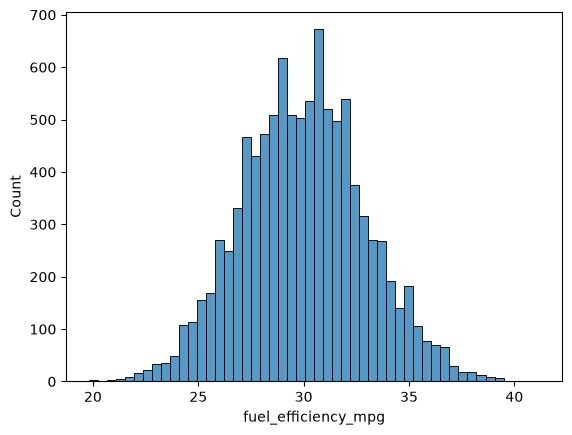

In [11]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)

In [12]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [13]:
df_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
6252,2015,USA,Diesel,Front-wheel drive,3,1900,5,239.0,3790,20.3,32.5
4684,1992,USA,Gasoline,All-wheel drive,4,2000,6,224.0,4380,21.8,29.1
1731,2022,USA,Hybrid,Front-wheel drive,3,2330,6,286.0,4090,17.8,34.1
4742,1997,Asia,Gasoline,Front-wheel drive,5,2300,6,NaN,4150,19.9,30.6
4521,2001,USA,Gasoline,Front-wheel drive,4,2340,6,269.0,4400,18.6,30.7
...,...,...,...,...,...,...,...,...,...,...,...
7895,2018,Asia,Gasoline,Rear-wheel drive,4,2280,6,242.0,4590,20.5,29.8
9590,1984,Europe,Gasoline,Front-wheel drive,2,2300,6,NaN,4240,18.1,25.1
7288,1989,USA,Gasoline,Front-wheel drive,3,2240,6,255.0,4190,17.2,27.7
278,2020,Europe,Gasoline,Rear-wheel drive,5,2430,6,254.0,4280,18.4,31.6


In [14]:
df_train = df_train.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

In [15]:
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

In [16]:
base = ['engine_displacement','horsepower','vehicle_weight','model_year']

df_train[base]

,engine_displacement,horsepower,vehicle_weight,model_year
0,1900,239.0,3790,2015
1,2000,224.0,4380,1992
2,2330,286.0,4090,2022
3,2300,NaN,4150,1997
4,2340,269.0,4400,2001
...,...,...,...,...
5995,2280,242.0,4590,2018
5996,2300,NaN,4240,1984
5997,2240,255.0,4190,1989
5998,2430,254.0,4280,2020


In [17]:
X_train = df_train[base].values
X_train

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]], shape=(6000, 4))

In [18]:
def train_linear_regression(X,y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones,X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

In [19]:
train_linear_regression(X_train, y_train)

(np.float64(nan), array([nan, nan, nan, nan]))

In [20]:
X_train_zero = df_train[base].fillna(0).values
X_train_mean = df_train[base].fillna(df['horsepower'].mean()).values

In [21]:
X_train_zero

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]], shape=(6000, 4))

In [22]:
w0_zero, w_zero = train_linear_regression(X_train_zero, y_train)
w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)

In [23]:
y_pred_zero = w0_zero + X_train.dot(w_zero)
y_pred_mean = w0_mean + X_train.dot(w_mean)

<Axes: ylabel='Count'>

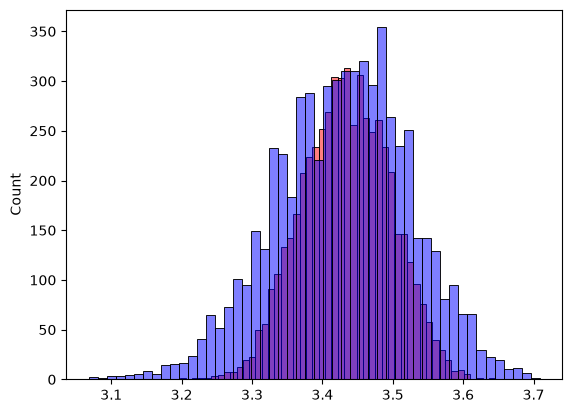

In [24]:
sns.histplot(y_pred_zero, color ='red', alpha =0.5, bins =50)
sns.histplot(y_train, color ='blue', alpha =0.5, bins =50)

<Axes: ylabel='Count'>

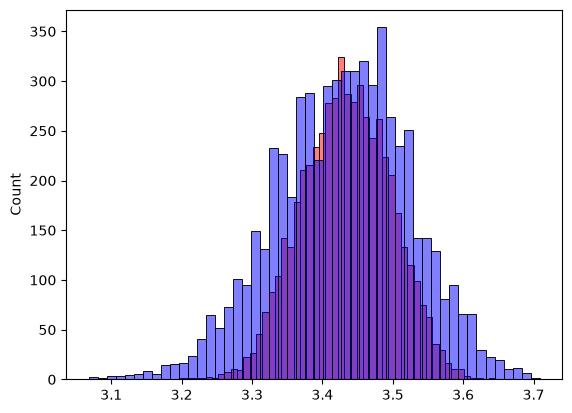

In [25]:
sns.histplot(y_pred_mean, color ='red', alpha =0.5, bins =50)
sns.histplot(y_train, color ='blue', alpha =0.5, bins =50)

In [36]:
def rmse(y, y_pred):
    error = y - y_pred
    se = error **2
    mse = se.mean()
    rs = np.sqrt(mse)
    
    return round(rs,3)
    

In [37]:
def prepare_X_zero(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X


In [38]:
def prepare_X_mean(df):
    df_num = df[base]
    df_num = df_num.fillna(df['horsepower'].mean())
    X = df_num.values
    return X

In [39]:
X_val_zero = prepare_X_zero(df_val)
y_pred_zero = w0_zero + X_val_zero.dot(w_zero)


In [40]:
X_val_mean = prepare_X_mean(df_val)
y_pred_mean = w0_mean + X_val_mean.dot(w_mean)

In [43]:
rmse(y_val, y_pred_zero)

np.float64(0.071)

In [44]:
rmse(y_val,y_pred_mean)

np.float64(0.071)

In [33]:
def train_linear_regression_reg(X,y,r = 0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones,X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

In [54]:
def rmse(y, y_pred):
    error = y - y_pred
    se = error **2
    mse = se.mean()
    rs = np.sqrt(mse)

    return rs

In [35]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = prepare_X_zero(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r = r)
    
    X_val = prepare_X_zero(df_val)
    y_pred = w0 + X_val.dot(w)   
    score = rmse(y_val, y_pred)

    print(r, w0, score)

0 -2.548879880787878 0.0715
0.01 -2.456525696928604 0.0715
0.1 -1.8524448492907521 0.0717
1 -0.535529553803343 0.0727
5 -0.1287451934306354 0.0733
10 -0.06603998348984993 0.0734
100 -0.006760761337059787 0.0735


In [ ]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test



In [58]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

scores = []

n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

for seed in seeds:

    np.random.seed(seed)

    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
    y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
    y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

    X_train = prepare_X_zero(df_train)
    w0, w = train_linear_regression(X_train, y_train)


    X_val = prepare_X_zero(df_val)
    y_pred = w0 + X_val.dot(w)

    score = rmse(y_val, y_pred)

    scores.append((seed, score))
    
for seed, score in scores:
    print(seed, score)

0 0.07222016116435427
1 0.07085480962390553
2 0.07001674410142289
3 0.07160947080490032
4 0.07121934602793346
5 0.07272074319560708
6 0.07363981939829586
7 0.07093670406151323
8 0.07159357901409524
9 0.07162894692635216


In [59]:
rmse_scores = [score for seed, score in scores]

std = np.std(rmse_scores)

print(std)

0.0009710806116187275


In [60]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

In [62]:
df_full_train = pd.concat([df_train,df_val])
df_full_train = df_full_train.reset_index(drop=True)
df_full_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2014,USA,Gasoline,Front-wheel drive,3,2320,6,246.0,4100,19.0,32.5
1,1998,Europe,Diesel,Rear-wheel drive,4,2230,6,252.0,4250,NaN,33.2
2,2008,Europe,Gasoline,Front-wheel drive,3,2700,6,276.0,4490,17.8,32.4
3,2004,USA,Gasoline,Front-wheel drive,2,2220,7,269.0,4060,20.0,29.9
4,1979,USA,Gasoline,All-wheel drive,3,2370,6,NaN,4690,22.0,26.4
...,...,...,...,...,...,...,...,...,...,...,...
7995,2023,USA,Hybrid,Front-wheel drive,4,2690,7,324.0,4510,17.9,35.7
7996,1998,Asia,Gasoline,Front-wheel drive,5,1920,5,190.0,4000,19.0,30.8
7997,1994,USA,Gasoline,Rear-wheel drive,3,1800,5,225.0,3980,19.6,29.1
7998,2009,Europe,Gasoline,Front-wheel drive,2,1970,5,232.0,3560,15.3,32.2


In [63]:
X_full_train = prepare_X_zero(df_full_train)
X_full_train

array([[2320.,  246., 4100., 2014.],
       [2230.,  252., 4250., 1998.],
       [2700.,  276., 4490., 2008.],
       ...,
       [1800.,  225., 3980., 1994.],
       [1970.,  232., 3560., 2009.],
       [2180.,  254., 3970., 2018.]], shape=(8000, 4))

In [64]:
y_full_train = np.concatenate([y_train, y_val])

In [65]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r = 0.001)

In [66]:
X_test = prepare_X_zero(df_test)
y_pred = w0 + X_test.dot(w)   
score = rmse(y_test, y_pred)

print( score)

0.07213088684591222
